In [1]:
import numpy as np
import matplotlib.pyplot as plt


def L(w_1, w_2):
    return 0.5 * (w_1 ** 4 - 16 * w_1 ** 2 + 5 * w_1 + w_2 ** 4 - 16 * w_2 ** 2 + 5 * w_2)


def grad_L(w_1, w_2):
    return 0.5 * np.array([4 * w_1 ** 3 - 32 * w_1 + 5, 4 * w_2 ** 3 - 32 * w_2 + 5])


def iterate(w_1_init, w_2_init, stepsize, num_iters, noise=None):
    w_1_k_values = [w_1_init]
    w_2_k_values = [w_2_init]

    for _ in range(num_iters):
        # w_k is the last value in the list
        w_1_k = w_1_k_values[-1]
        w_2_k = w_2_k_values[-1]

        grad_l_w_k = grad_L(w_1_k, w_2_k)

        if noise:
            grad_l_w_k += np.random.normal(scale=noise, size=2)

        w_1_k_values.append(w_1_k - stepsize * grad_l_w_k[0])
        w_2_k_values.append(w_2_k - stepsize * grad_l_w_k[1])

    return np.array(w_1_k_values), np.array(w_2_k_values)


def plot_gd_values(w_1_values, w_2_values, num_points=100, noise=None):
    w_1_points = np.linspace(-4.5, 4.5, num=num_points)
    w_2_points = np.linspace(-4.5, 4.5, num=num_points)

    w_1_points_grid, w_2_points_grid = np.meshgrid(w_1_points, w_2_points)
    loss_values = L(w_1_points_grid, w_2_points_grid)

    plt.figure(figsize=(7, 7))
    plt.imshow(loss_values, extent=(-4.5, 4.5, -4.5, 4.5), origin='lower', cmap="viridis")
    plt.plot(w_1_values, w_2_values, marker="s", linestyle="dotted", color="red")
    plt.colorbar()
    plt.title(f"GD {f"with noise ($\\sigma$={noise}) " if noise else ""}Styblinski-Tang function")
    plt.xlabel("$w_1$")
    plt.ylabel("$w_2$")
    plt.show()


In [2]:
stepsize = .02

w_1_init = -1.4
w_2_init = 0.5

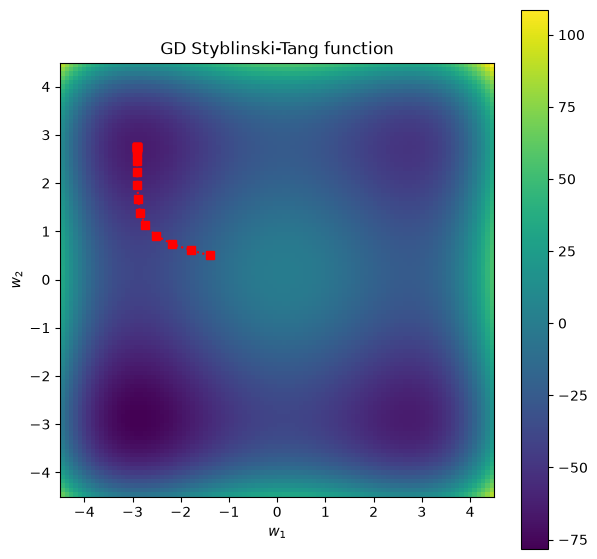

In [3]:
w_1_values, w_2_values = iterate(w_1_init, w_2_init, stepsize, 20)

plot_gd_values(w_1_values, w_2_values)

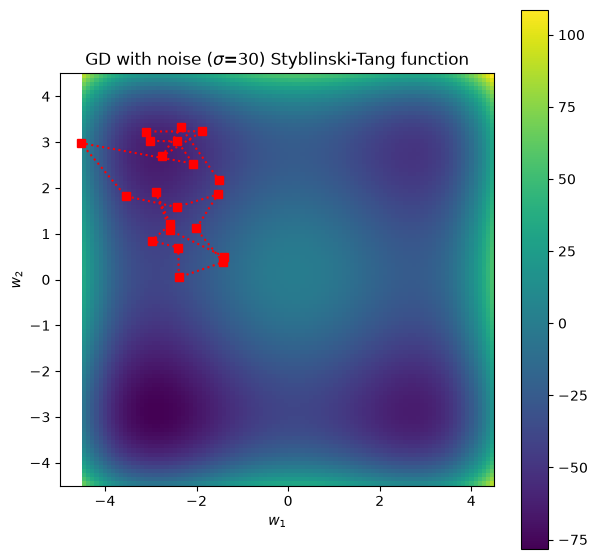

In [4]:
noise = 30
w_1_values, w_2_values = iterate(w_1_init, w_2_init, stepsize, 20, noise=noise)

plot_gd_values(w_1_values, w_2_values, noise=noise)